# 03 · Exploratory Data Analysis
**CIS 5450 – EV Energy and Thermal Monitoring · Phase 1**

Works only on the processed outputs of notebook 02 (`telemetry_10s.parquet`, `trips.parquet`), so teammates can run it without the raw data.

Sections:
1. Fleet overview & data imbalance
2. Missingness of the cleaned signals
3. Signal distributions & correlations (driving rows)
4. Trip-level features (input to driving-regime clustering, RQ1)
5. Energy consumption vs speed, temperature, vehicle (RQ3)
6. Battery thermal behaviour & a data-driven thermal-demand threshold (RQ2/RQ4)
7. Seasonality
8. Summary of key numbers → `reports/eda_summary.md`

In [1]:
# Run once per environment (safe to re-run)
%pip install -q duckdb pyarrow pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# project root = folder that contains src/ev_pipeline.py (works from /notebooks or the root)
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src" / "ev_pipeline.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import ev_pipeline as ev

P = ev.project_paths(ROOT)
# Raw data (~1.2 GB) can live outside OneDrive: set env var EV_RAW_DIR before starting Jupyter
RAW_DIR = Path(os.environ.get("EV_RAW_DIR", P["raw"]))
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=FutureWarning)

def savefig(name):
    plt.savefig(P["figures"] / f"{name}.png", dpi=130, bbox_inches="tight")

print("Project root:", ROOT)
print("Raw data dir:", RAW_DIR)

tel = pd.read_parquet(P["processed"] / "telemetry_10s.parquet")
trips = pd.read_parquet(P["processed"] / "trips.parquet")
tel["ts"] = pd.to_datetime(tel["ts"])
drive = tel[tel["state"] == "driving"]
CANON = [c for c in ev.CANONICAL_SIGNALS if c in tel.columns]
print(f"telemetry: {tel.shape}, trips: {trips.shape}")
print("canonical signals available:", CANON)
summary = {}   # key numbers collected for the written summary

Project root: C:\Users\sumit\OneDrive\Desktop\Big_Data\Project
Raw data dir: C:\Users\sumit\OneDrive\Desktop\Big_Data\Project\data\raw


telemetry: (911145, 28), trips: (2389, 40)
canonical signals available: ['speed', 'soc', 'bat_temp', 'bat_temp_min', 'hv_voltage', 'ambient_temp', 'coolant_temp', 'motor_temp', 'bat_inlet_temp', 'bat_outlet_temp', 'interior_temp', 'hv_aux_power', 'rotor_temp']


## 1. Fleet overview

In [3]:
fleet = tel.groupby("vehicle_id").agg(first=("ts", "min"), last=("ts", "max"),
                                      buckets=("ts", "size"),
                                      active_days=("ts", lambda s: s.dt.normalize().nunique()))
fleet["driving_h"]  = tel[tel.state == "driving"].groupby("vehicle_id").size() * 10 / 3600
fleet["charging_h"] = tel[tel.state == "charging"].groupby("vehicle_id").size() * 10 / 3600
fleet = fleet.join(trips.groupby("vehicle_id").agg(n_trips=("trip_id", "size"), km=("distance_km", "sum")))
summary["n_vehicles"] = len(fleet); summary["n_trips"] = int(fleet.n_trips.sum())
summary["total_km"] = round(float(fleet.km.sum()), 0)
summary["trips_min_max_per_vehicle"] = (int(fleet.n_trips.min()), int(fleet.n_trips.max()))
fleet.round({"driving_h": 1, "charging_h": 1, "km": 1})

,first,last,buckets,active_days,driving_h,charging_h,n_trips,km
vehicle_id,,,,,,,,
CUP1,2022-11-15 09:37:00,2023-04-24 15:10:00,66564,109,117.7,43.5,395,4049.4
CUP2,2022-11-21 08:43:10,2023-05-04 21:36:40,27887,70,43.8,27.4,187,1858.8
CUP3,2022-11-17 09:35:10,2023-04-23 12:23:50,7228,30,12.3,5.8,46,540.9
CUP4,2022-11-15 09:42:30,2023-04-14 14:23:20,35923,91,62.7,28.0,226,2332.6
CUP5,2022-11-10 17:06:10,2023-04-23 18:38:00,23734,82,47.6,10.6,188,1343.2
ID1,2021-02-01 20:20:30,2023-06-13 07:50:10,464457,369,220.8,431.5,511,15448.1
ID2,2021-07-26 14:16:10,2023-10-10 10:55:10,285352,339,301.7,357.8,836,18089.1


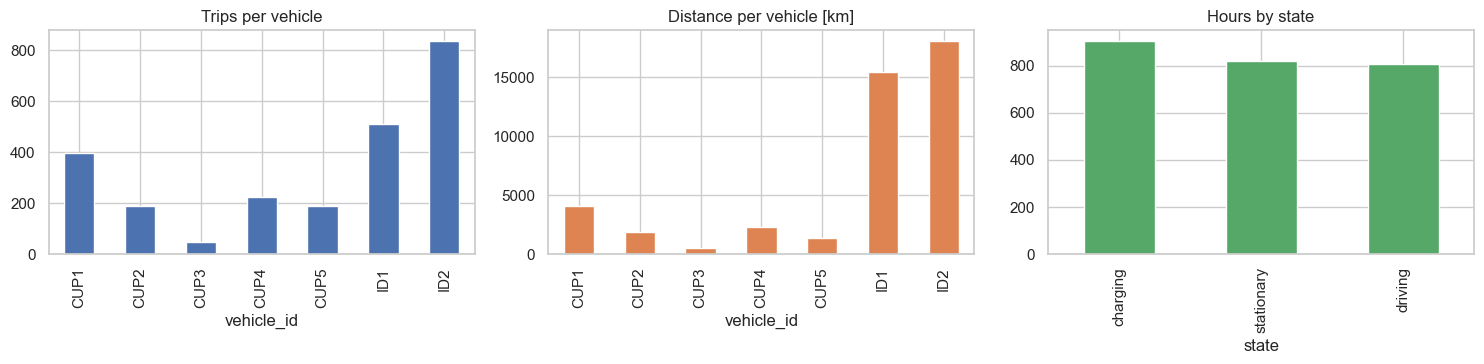

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
fleet["n_trips"].plot.bar(ax=ax[0], title="Trips per vehicle", color="C0")
fleet["km"].plot.bar(ax=ax[1], title="Distance per vehicle [km]", color="C1")
tel["state"].value_counts().mul(10 / 3600).plot.bar(ax=ax[2], title="Hours by state", color="C2")
plt.tight_layout(); savefig("03_fleet_overview"); plt.show()

## 2. Missingness after cleaning

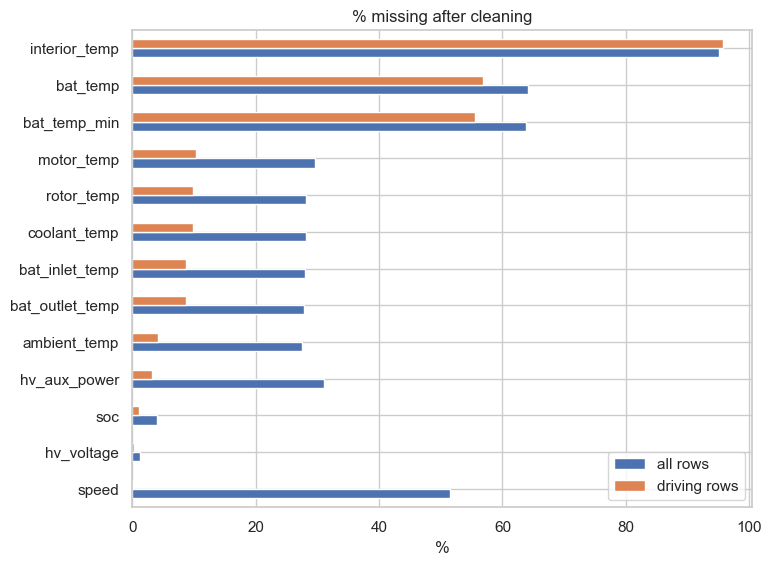

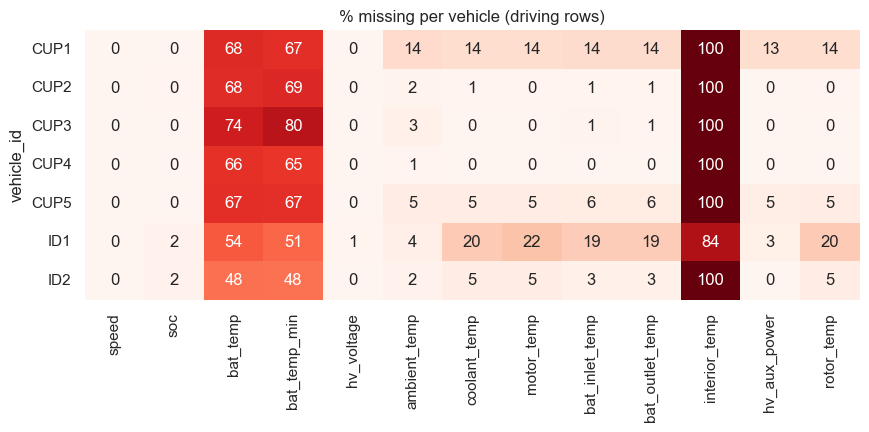

In [5]:
miss = pd.DataFrame({"all rows": tel[CANON].isna().mean(), "driving rows": drive[CANON].isna().mean()}) * 100
ax = miss.sort_values("driving rows").plot.barh(figsize=(8, 0.4 * len(miss) + 1), title="% missing after cleaning")
ax.set_xlabel("%"); savefig("03_missingness"); plt.show()
by_veh = drive.groupby("vehicle_id")[CANON].apply(lambda d: d.isna().mean() * 100)
plt.figure(figsize=(10, 3.5)); sns.heatmap(by_veh, annot=True, fmt=".0f", cmap="Reds", cbar=False)
plt.title("% missing per vehicle (driving rows)"); savefig("03_missingness_by_vehicle"); plt.show()

## 3. Signal distributions & correlations (driving rows)

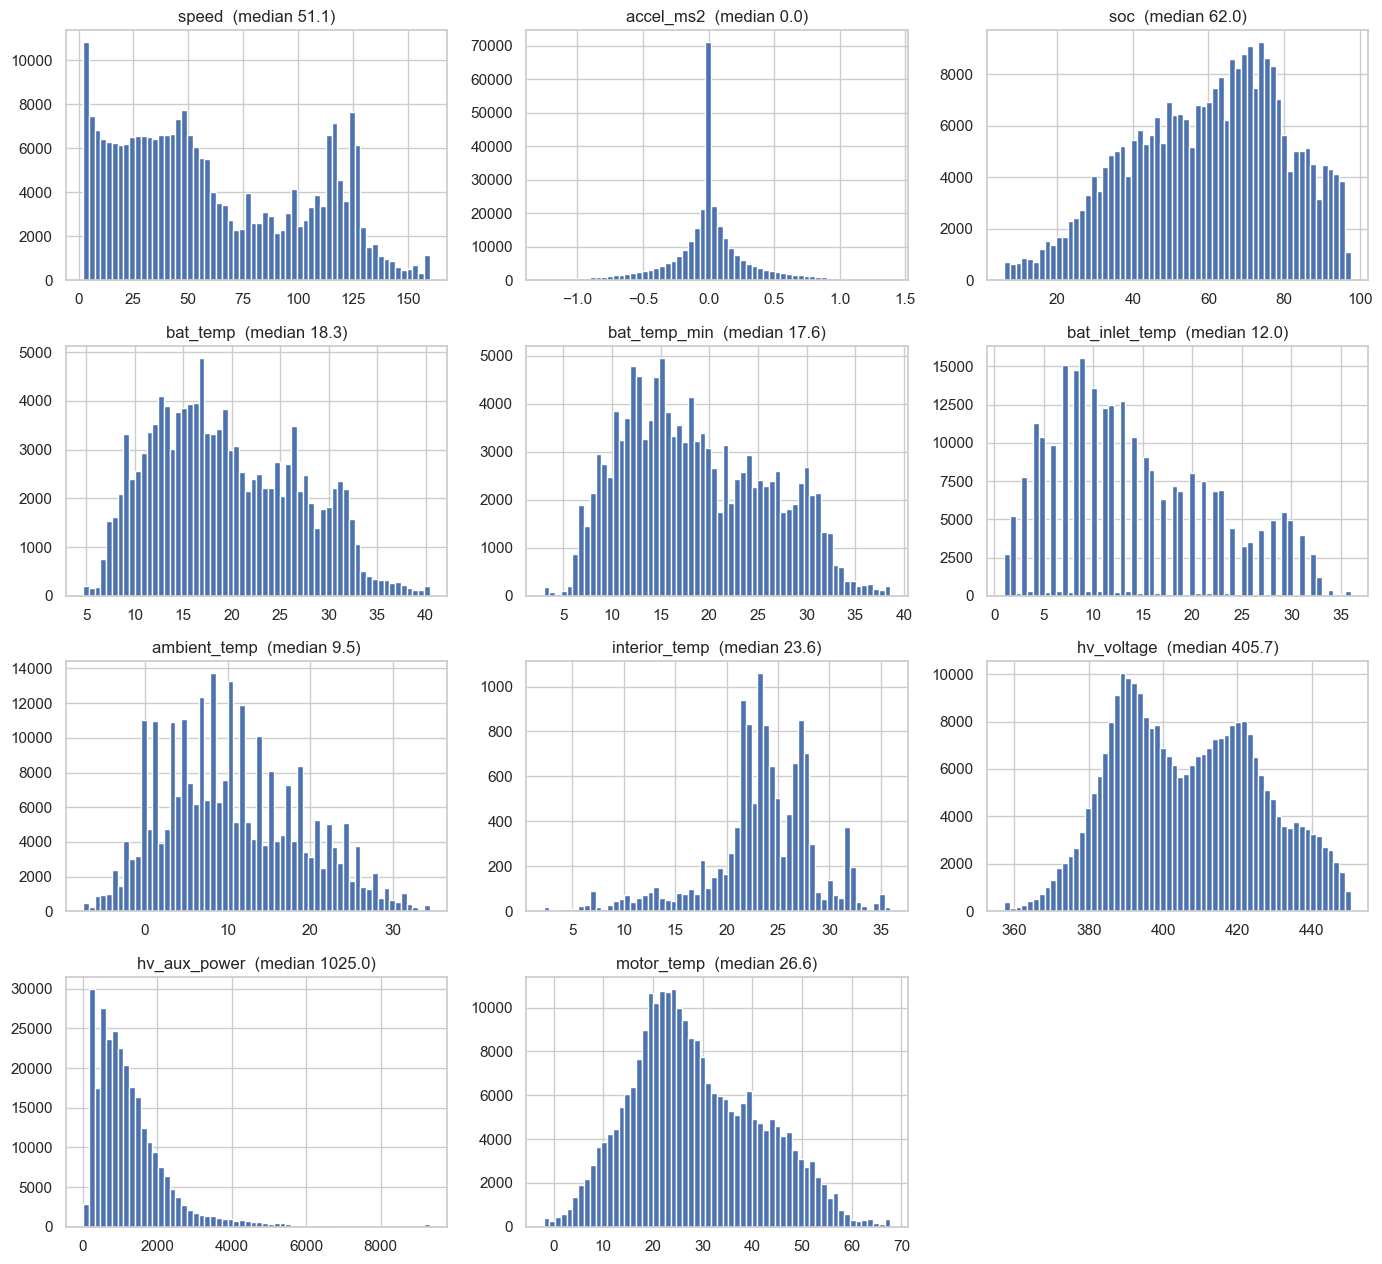

,count,mean,std,min,1%,5%,50%,95%,99%,max
speed,289977.0,54.21,43.75,0.00,0.00,0.00,45.28,127.19,147.99,160.34
accel_ms2,287033.0,0.00,0.32,-2.02,-0.92,-0.56,0.00,0.56,0.95,3.26
soc,287144.0,59.65,20.38,4.00,12.00,24.40,62.00,91.20,95.20,99.60
bat_temp,125240.0,19.39,7.41,2.60,7.01,8.77,18.34,31.96,36.51,43.14
bat_temp_min,129172.0,18.65,7.36,-0.20,6.46,8.19,17.62,31.25,34.77,41.10
bat_inlet_temp,265047.0,14.09,8.14,0.03,1.50,3.00,12.00,30.00,32.00,66.17
ambient_temp,278226.0,10.52,8.27,-11.00,-4.50,-1.50,9.50,25.50,30.00,39.50
interior_temp,12447.0,23.38,5.25,0.20,6.80,12.40,23.60,31.80,34.40,38.20
hv_voltage,289411.0,406.76,19.50,330.64,368.57,377.80,405.70,440.49,447.07,494.58
hv_aux_power,281081.0,1297.32,1120.35,0.00,150.00,288.89,1025.00,3320.00,5843.17,12900.00


In [6]:
cols = [c for c in ["speed", "accel_ms2", "soc", "bat_temp", "bat_temp_min", "bat_inlet_temp",
                    "ambient_temp", "interior_temp", "hv_voltage", "hv_aux_power", "motor_temp",
                    "motor_rpm", "hv_current", "power_kw"] if c in drive]
n = len(cols); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows), squeeze=False)
for ax, c in zip(axes.ravel(), cols):
    d = drive[c].dropna()
    if c == "speed":
        d = d[d > 2]
    ax.hist(d.clip(d.quantile(.001), d.quantile(.999)), bins=60, color="C0")
    ax.set_title(f"{c}  (median {d.median():.1f})")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); savefig("03_signal_distributions"); plt.show()
drive[cols].describe(percentiles=[.01, .05, .5, .95, .99]).T.round(2)

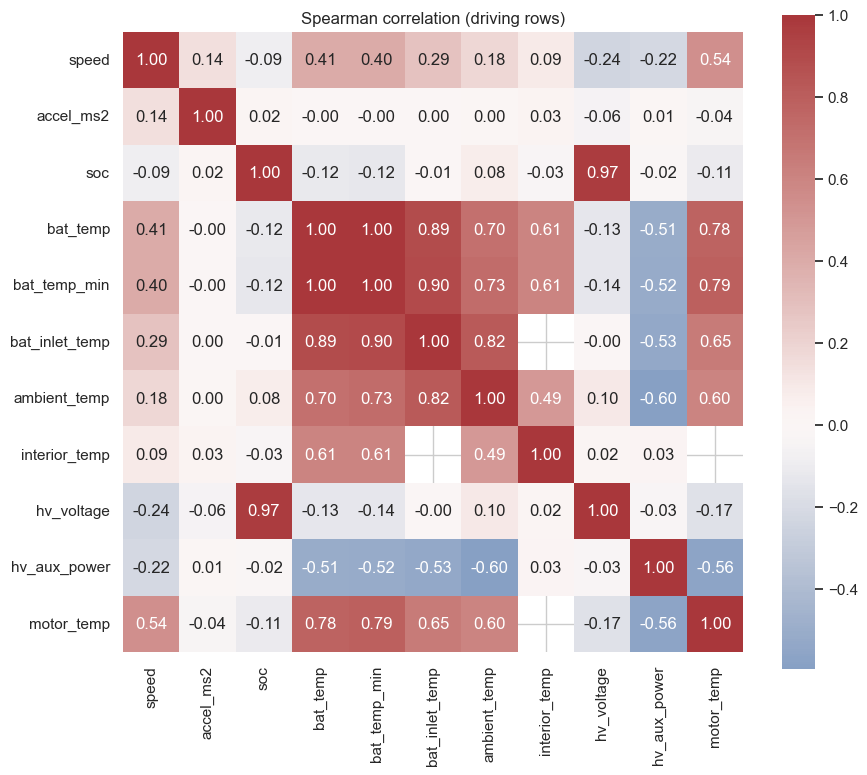

In [7]:
corr = drive[cols].corr(method="spearman")
plt.figure(figsize=(10, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Spearman correlation (driving rows)"); savefig("03_correlation"); plt.show()

## 4. Trip-level features (input for driving-regime clustering, RQ1)
These are the variables the clustering team (Phase 2) will use: speed, stop fraction, acceleration, duration, RPM.

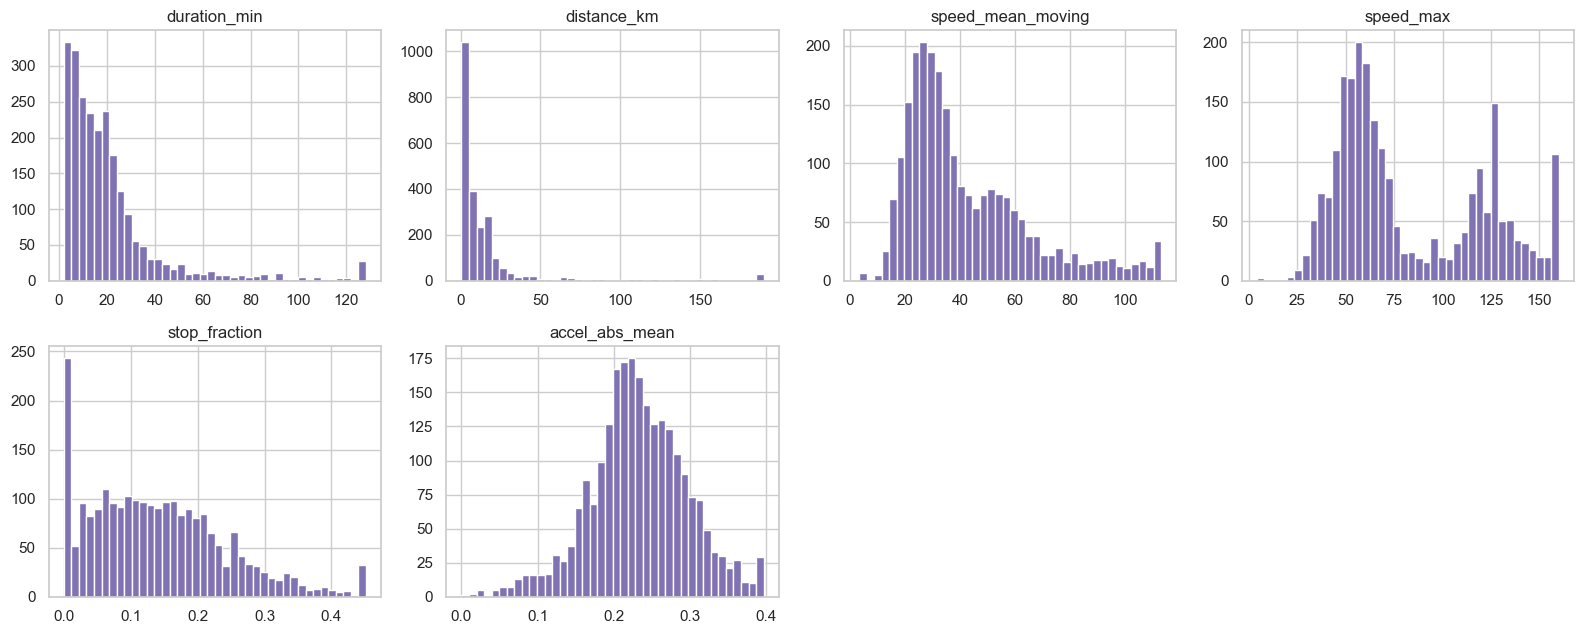

,count,mean,std,min,25%,50%,75%,max
duration_min,2389.0,21.51,23.82,2.00,7.67,15.33,24.50,210.00
distance_km,2389.0,18.28,35.38,0.50,2.72,6.80,16.95,311.78
speed_mean_moving,2389.0,42.40,23.15,3.30,25.72,34.71,53.98,130.46
speed_max,2389.0,82.26,37.64,3.94,52.63,66.27,117.53,160.34
stop_fraction,2389.0,0.14,0.10,0.00,0.06,0.13,0.20,0.62
accel_abs_mean,2389.0,0.23,0.07,0.00,0.20,0.23,0.27,0.67


In [8]:
tcols = [c for c in ["duration_min", "distance_km", "speed_mean_moving", "speed_max", "stop_fraction",
                     "accel_abs_mean", "rpm_abs_mean"] if c in trips]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.ravel(), tcols):
    d = trips[c].dropna()
    ax.hist(d.clip(upper=d.quantile(.99)), bins=40, color="C4"); ax.set_title(c)
for ax in axes.ravel()[len(tcols):]:
    ax.axis("off")
plt.tight_layout(); savefig("03_trip_feature_distributions"); plt.show()
summary["trip_duration_median_min"] = round(float(trips.duration_min.median()), 1)
summary["trip_distance_median_km"] = round(float(trips.distance_km.median()), 1)
trips[tcols].describe().T.round(2)

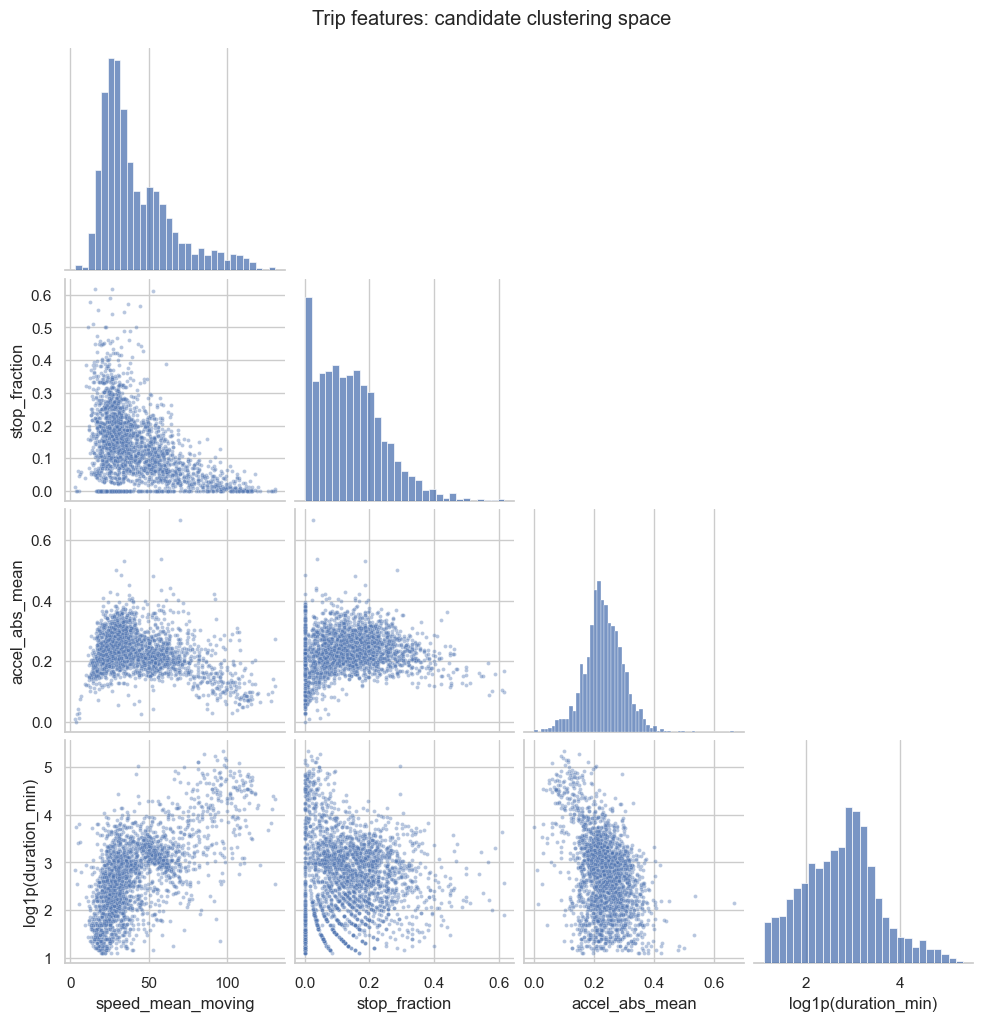

In [9]:
pair = [c for c in ["speed_mean_moving", "stop_fraction", "accel_abs_mean", "duration_min"] if c in trips]
g = sns.pairplot(trips[pair].assign(duration_min=lambda d: np.log1p(d.duration_min)).rename(
        columns={"duration_min": "log1p(duration_min)"}), corner=True, plot_kws=dict(s=8, alpha=.4))
g.fig.suptitle("Trip features: candidate clustering space", y=1.02)
plt.savefig(P["figures"] / "03_trip_feature_pairplot.png", dpi=110, bbox_inches="tight"); plt.show()

## 5. Energy consumption (RQ1 / RQ3)
SOC% per 100 km is noisy for short trips (SOC resolution), so we compare the 5 km and 20 km minimum-distance filters the proposal discusses.

trips usable for energy: >=5 km: 1374  |  >=20 km: 420
vehicle_id
CUP1     53
CUP2     17
CUP3      4
CUP4     25
CUP5      9
ID1     182
ID2     130
Name: trips >= 20 km, dtype: int64


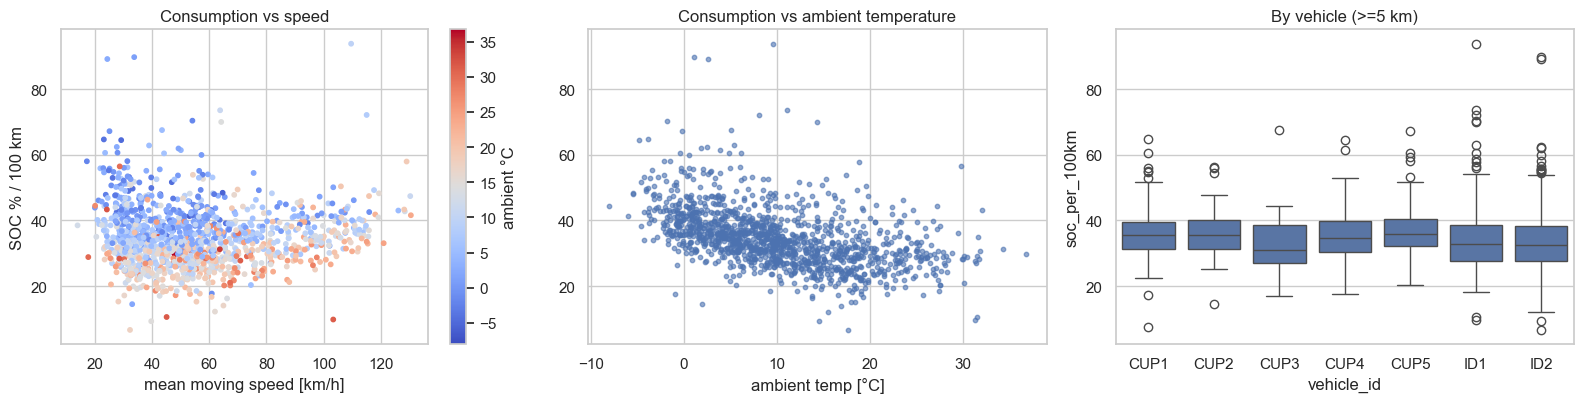

,spearman vs SOC%/100km
soc_per_100km,1.00
speed_mean_moving,-0.02
stop_fraction,0.10
accel_abs_mean,0.05
ambient_temp_mean,-0.56
bat_temp_start,-0.39


In [10]:
if "soc_per_100km" in trips:
    e5 = trips[trips.energy_valid_5km]
    e20 = trips[trips.energy_valid_20km]
    summary["trips_valid_energy_5km"] = len(e5); summary["trips_valid_energy_20km"] = len(e20)
    summary["soc_per_100km_median_5km"] = round(float(e5.soc_per_100km.median()), 2)
    print(f"trips usable for energy: >=5 km: {len(e5)}  |  >=20 km: {len(e20)}")
    print(e20.groupby("vehicle_id").size().rename("trips >= 20 km"))

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    sc = ax[0].scatter(e5.speed_mean_moving, e5.soc_per_100km, c=e5.get("ambient_temp_mean"), cmap="coolwarm", s=10)
    ax[0].set_xlabel("mean moving speed [km/h]"); ax[0].set_ylabel("SOC % / 100 km"); ax[0].set_title("Consumption vs speed")
    if "ambient_temp_mean" in e5: plt.colorbar(sc, ax=ax[0], label="ambient °C")
    if "ambient_temp_mean" in e5:
        ax[1].scatter(e5.ambient_temp_mean, e5.soc_per_100km, s=10, alpha=.6)
        ax[1].set_xlabel("ambient temp [°C]"); ax[1].set_title("Consumption vs ambient temperature")
    sns.boxplot(data=e5, x="vehicle_id", y="soc_per_100km", ax=ax[2], color="C0"); ax[2].set_title("By vehicle (>=5 km)")
    ax[1].set_ylim(ax[0].get_ylim())
    plt.tight_layout(); savefig("03_energy_consumption"); plt.show()
    display(e5[["soc_per_100km", "speed_mean_moving", "stop_fraction", "accel_abs_mean",
                *[c for c in ["ambient_temp_mean", "bat_temp_start"] if c in e5]]].corr(method="spearman")
            ["soc_per_100km"].round(2).to_frame("spearman vs SOC%/100km"))

In [11]:
if "kwh_per_100km" in trips:
    e = trips[trips.energy_valid_5km]
    print("HV current available -> kWh/100 km median:", round(e.kwh_per_100km.median(), 1))
    plt.figure(figsize=(5, 4)); plt.scatter(e.soc_per_100km, e.kwh_per_100km, s=8)
    plt.xlabel("SOC %/100 km"); plt.ylabel("kWh/100 km"); plt.title("SOC-based vs current-based energy")
    savefig("03_soc_vs_kwh"); plt.show()
    summary["kwh_per_100km_median"] = round(float(e.kwh_per_100km.median()), 1)

## 6. Battery thermal behaviour (RQ2 / RQ4)

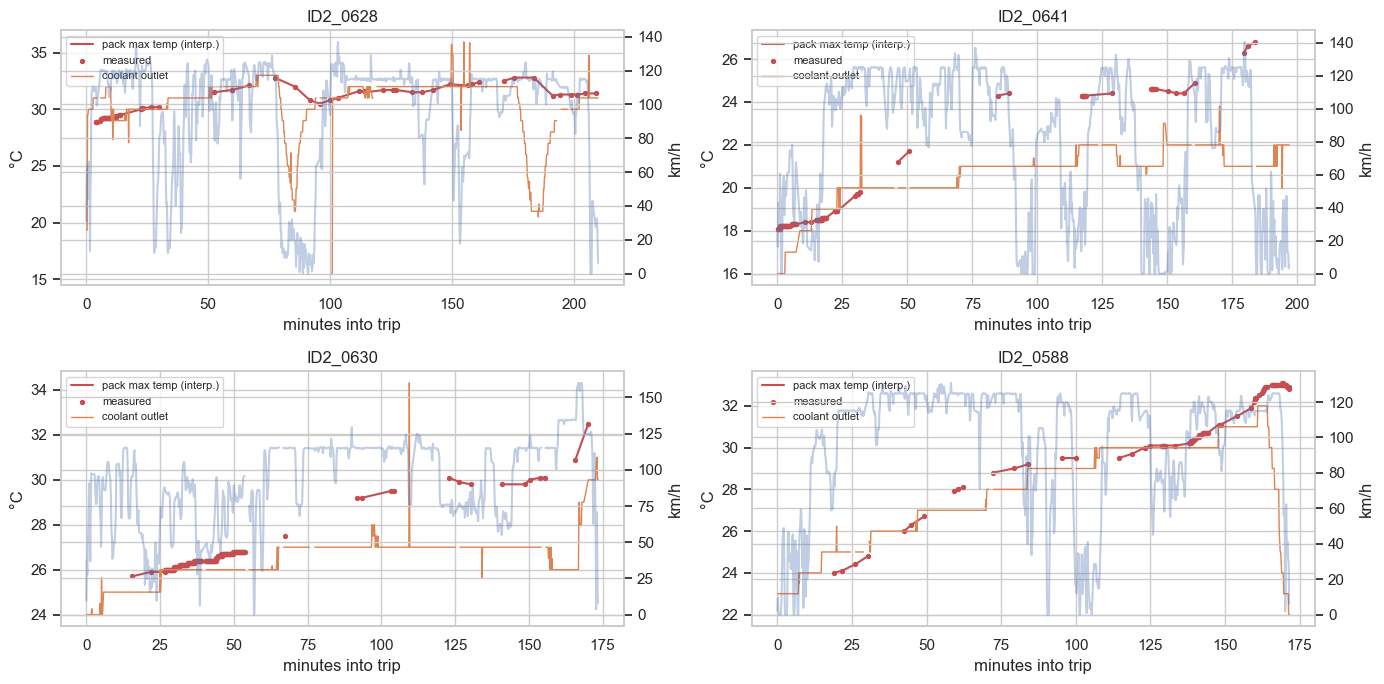

In [12]:
TEMP = "bat_temp"
n_obs = tel[tel.trip_id.notna()].groupby("trip_id")[f"{TEMP}_observed"].sum() if f"{TEMP}_observed" in tel else None
cand = trips if n_obs is None else trips[trips.trip_id.map(n_obs).fillna(0) >= 20]
longest = cand.nlargest(4, "duration_min").trip_id
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=False)
for ax, tid in zip(axes.ravel(), longest):
    d = tel[tel.trip_id == tid]
    ax.plot(d.trip_elapsed_s / 60, d[TEMP], color="C3", label="pack max temp (interp.)")
    obs = d[d.get(f"{TEMP}_observed", pd.Series(True, index=d.index))]
    ax.scatter(obs.trip_elapsed_s / 60, obs[TEMP], color="C3", s=8, label="measured")
    if "bat_outlet_temp" in d:
        ax.plot(d.trip_elapsed_s / 60, d.bat_outlet_temp, color="C1", lw=1, label="coolant outlet")
    ax.legend(loc="upper left", fontsize=8)
    ax2 = ax.twinx(); ax2.plot(d.trip_elapsed_s / 60, d.speed, color="C0", alpha=.35, label="speed")
    ax.set_title(tid); ax.set_xlabel("minutes into trip"); ax.set_ylabel("°C"); ax2.set_ylabel("km/h")
plt.tight_layout(); savefig("03_example_trip_temperature"); plt.show()

(t, t+5min) pairs inside trips: 76,070


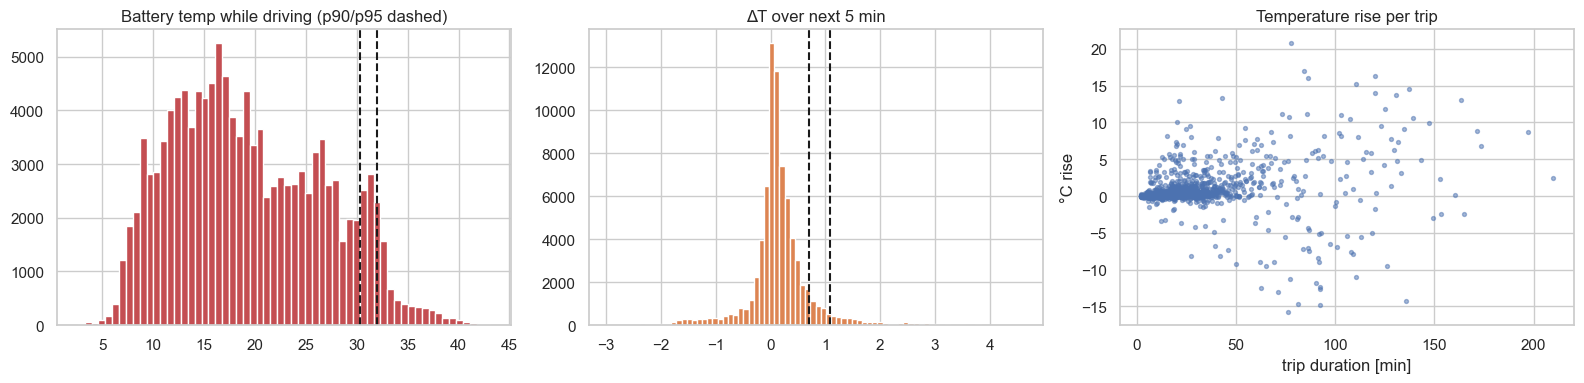

Candidate rule: D_T = 1 if T(t+5) >= 30.3 °C (p90) OR ΔT5 >= 1.09 °C (p95)
-> positive rate 16.4% (class imbalance to handle in Phase 3)


In [13]:
# 5-minute-ahead temperature change within trips (the RQ2 target)
H = pd.Timedelta(minutes=5)
cur = tel.loc[tel.trip_id.notna() & tel[TEMP].notna(), ["trip_id", "ts", TEMP, "speed"]]
fut = cur[["trip_id", "ts", TEMP]].assign(ts=lambda d: d.ts - H).rename(columns={TEMP: "temp_future"})
pairs = cur.merge(fut, on=["trip_id", "ts"], how="inner")
pairs["dT_5min"] = pairs["temp_future"] - pairs[TEMP]
print(f"(t, t+5min) pairs inside trips: {len(pairs):,}")

thr_T  = drive[TEMP].quantile([.90, .95]).round(1)
thr_dT = pairs["dT_5min"].quantile([.90, .95, .99]).round(2)
summary["bat_temp_p90_p95"] = thr_T.tolist(); summary["dT5_p90_p95_p99"] = thr_dT.tolist()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(drive[TEMP].dropna(), bins=60, color="C3"); [ax[0].axvline(v, ls="--", c="k") for v in thr_T]
ax[0].set_title("Battery temp while driving (p90/p95 dashed)")
ax[1].hist(pairs.dT_5min.clip(-3, 5), bins=80, color="C1"); [ax[1].axvline(v, ls="--", c="k") for v in thr_dT[:2]]
ax[1].set_title("ΔT over next 5 min")
ax[2].scatter(trips.duration_min, trips[f"{TEMP}_rise"], s=8, alpha=.5)
ax[2].set_xlabel("trip duration [min]"); ax[2].set_ylabel("°C rise"); ax[2].set_title("Temperature rise per trip")
plt.tight_layout(); savefig("03_thermal"); plt.show()

# Candidate thermal-demand label D_T for RQ4 (team to confirm the rule)
D_T = (pairs.temp_future >= thr_T.loc[.90]) | (pairs.dT_5min >= thr_dT.loc[.95])
summary["D_T_positive_rate"] = round(float(D_T.mean()), 3)
print(f"Candidate rule: D_T = 1 if T(t+5) >= {thr_T.loc[.90]} °C (p90) OR ΔT5 >= {thr_dT.loc[.95]} °C (p95)")
print(f"-> positive rate {D_T.mean():.1%} (class imbalance to handle in Phase 3)")

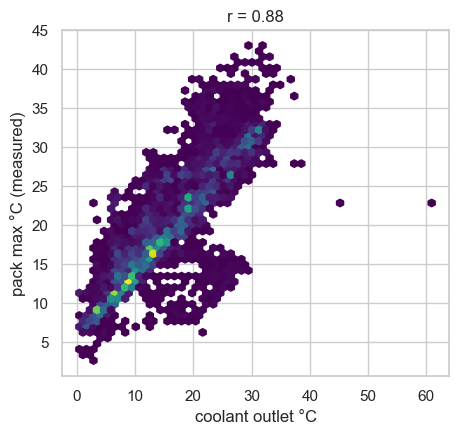

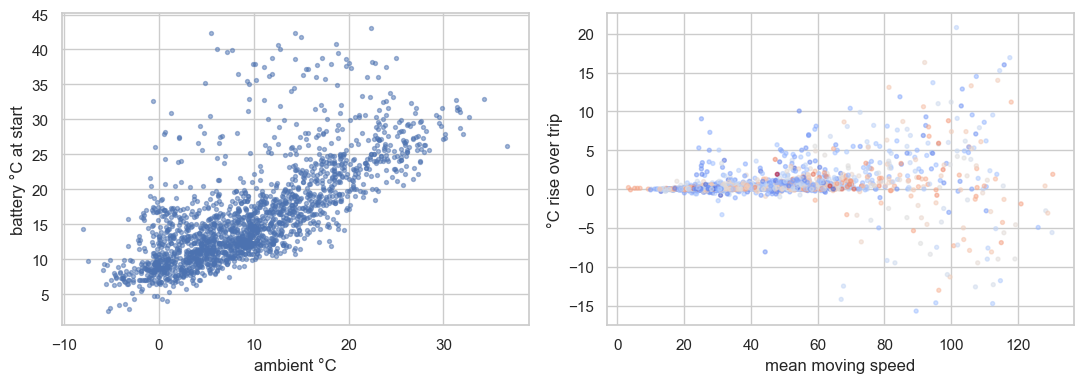

In [14]:
# How well does the dense coolant-outlet temperature track pack max temperature? (backup target)
if "bat_outlet_temp" in drive:
    m = drive[drive.get(f"{TEMP}_observed", True) & drive.bat_outlet_temp.notna()]
    r = m[[TEMP, "bat_outlet_temp"]].corr().iloc[0, 1]
    summary["corr_packmax_vs_outlet"] = round(float(r), 3)
    summary["share_driving_rows_with_bat_temp"] = round(float(drive[TEMP].notna().mean()), 3)
    summary["share_driving_rows_with_outlet_temp"] = round(float(drive.bat_outlet_temp.notna().mean()), 3)
    plt.figure(figsize=(5, 4.5)); plt.hexbin(m.bat_outlet_temp, m[TEMP], gridsize=50, mincnt=1, cmap="viridis")
    plt.xlabel("coolant outlet °C"); plt.ylabel("pack max °C (measured)"); plt.title(f"r = {r:.2f}")
    savefig("03_packmax_vs_outlet"); plt.show()

# Does temperature at trip start depend on ambient temperature? (motivates using ambient as a feature)
if "ambient_temp_mean" in trips:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(trips.ambient_temp_mean, trips[f"{TEMP}_start"], s=8, alpha=.5)
    ax[0].set_xlabel("ambient °C"); ax[0].set_ylabel("battery °C at start")
    ax[1].scatter(trips.speed_mean_moving, trips[f"{TEMP}_rise"], s=8, alpha=.5, c=trips.ambient_temp_mean, cmap="coolwarm")
    ax[1].set_xlabel("mean moving speed"); ax[1].set_ylabel("°C rise over trip")
    plt.tight_layout(); savefig("03_thermal_vs_ambient"); plt.show()

## 7. Seasonality & time of day

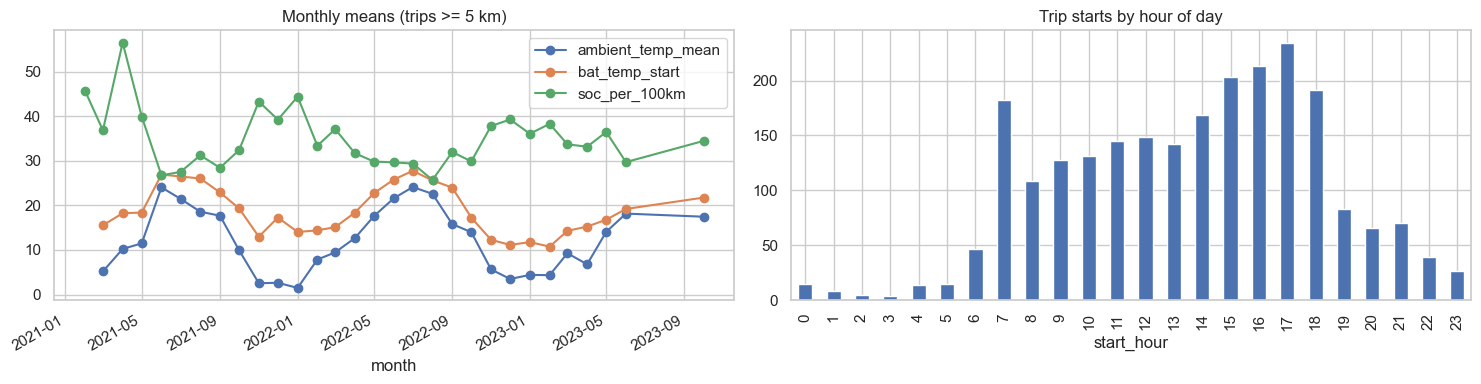

,ambient_temp_mean,bat_temp_start,soc_per_100km,trip_id
month,,,,
2021-02-01,NaN,NaN,45.66,10
2021-03-01,5.20,15.55,36.84,19
2021-04-01,10.23,18.24,56.49,7
2021-05-01,11.49,18.40,39.92,6
2021-06-01,24.04,26.92,26.75,21
2021-07-01,21.47,26.48,27.51,14
2021-08-01,18.59,26.04,31.23,53
2021-09-01,17.69,22.90,28.43,18
2021-10-01,9.95,19.33,32.40,53


In [15]:
trips["month"] = pd.to_datetime(trips.start_ts).dt.to_period("M").dt.to_timestamp()
cols_m = {c: "mean" for c in ["ambient_temp_mean", f"{TEMP}_start", "soc_per_100km"] if c in trips}
monthly = trips[trips.get("energy_valid_5km", True)].groupby("month").agg({**cols_m, "trip_id": "count"})
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
monthly.drop(columns="trip_id").plot(ax=ax[0], marker="o", title="Monthly means (trips >= 5 km)")
trips.start_hour.value_counts().sort_index().plot.bar(ax=ax[1], title="Trip starts by hour of day", color="C0")
plt.tight_layout(); savefig("03_seasonality"); plt.show()
monthly.round(2)

## 8. Summary for the team

In [16]:
lines = ["# EDA summary (auto-generated by 03_eda.ipynb)", ""]
for k, v in summary.items():
    lines.append(f"- **{k}**: {v}")
lines += ["", "## Notes for Phase 2/3",
          "- Trip counts are very uneven across vehicles: use per-vehicle permutation tests and GroupKFold by vehicle or trip.",
          "- SOC%/100km is only reliable for longer trips; compare the 5 km and 20 km filters.",
          "- The candidate thermal-demand rule above is data-driven (p90 temperature / p95 5-min rise); confirm as a team.",
          "- Build forecasting features only from rows up to the prediction time (no whole-trip aggregates)."]
(P["reports"] / "eda_summary.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

# EDA summary (auto-generated by 03_eda.ipynb)

- **n_vehicles**: 7
- **n_trips**: 2389
- **total_km**: 43662.0
- **trips_min_max_per_vehicle**: (46, 836)
- **trip_duration_median_min**: 15.3
- **trip_distance_median_km**: 6.8
- **trips_valid_energy_5km**: 1374
- **trips_valid_energy_20km**: 420
- **soc_per_100km_median_5km**: 33.8
- **bat_temp_p90_p95**: [30.3, 32.0]
- **dT5_p90_p95_p99**: [0.7, 1.09, 2.49]
- **D_T_positive_rate**: 0.164
- **corr_packmax_vs_outlet**: 0.876
- **share_driving_rows_with_bat_temp**: 0.431
- **share_driving_rows_with_outlet_temp**: 0.913

## Notes for Phase 2/3
- Trip counts are very uneven across vehicles: use per-vehicle permutation tests and GroupKFold by vehicle or trip.
- SOC%/100km is only reliable for longer trips; compare the 5 km and 20 km filters.
- The candidate thermal-demand rule above is data-driven (p90 temperature / p95 5-min rise); confirm as a team.
- Build forecasting features only from rows up to the prediction time (no whole-trip aggre